# Importancia de variables del buscador

**Tesis:** *Desarrollo y evaluación de un chatbot educativo basado en IA generativa y RAG para reforzar el aprendizaje de cinemática preuniversitaria en una academia de Chachapoyas* — Elmer Dante Rojas Zuta (MIA-UNI).

**Configuración analizada:** la que dejó el sprint anterior, es decir, el buscador **V1** (BM25 + palabras vacías + raíces, sin enrutador) sobre el **corpus v5.1**.

Se estudian dos tipos de variables:

- **A. De los datos:** ¿qué campo de la ficha ayuda a encontrarla? Se usa ablación «quitar uno».
- **B. De las preguntas:** ¿qué características hacen fallar al buscador? Se usa un modelo explicativo con importancia por permutación.

El notebook reutiliza `experiments/importancia_variables/ejecutar.py`, así que los números coinciden con el README. La evaluación final no se usa.

In [1]:
import sys, json, importlib.util
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
spec = importlib.util.spec_from_file_location("iv", RAIZ / "experiments/importancia_variables/ejecutar.py")
iv = importlib.util.module_from_spec(spec); spec.loader.exec_module(iv)
fe = iv.fe
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import eda_utils as u
u.estilo(); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 80)

corpus, preguntas, fuente = fe.cargar(None)
dev = preguntas[preguntas.particion == "desarrollo"].reset_index(drop=True)
val = preguntas[preguntas.particion == "validacion"].reset_index(drop=True)
iv.R.mkdir(parents=True, exist_ok=True)
print(f"Batería usada: {fuente} · desarrollo {len(dev)} · validación {len(val)}")

Batería usada: completa (privada) · desarrollo 180 · validación 72


## A. Variables de los datos: ¿qué campo de la ficha ayuda a encontrarla?

Cada línea del texto indexado de una ficha pertenece a un campo. Así se ve una ficha de teoría y una de ejemplo resuelto, separadas por campos:

In [2]:
for fid in ["CIN-MRU-T011", "CIN-MRU-E001"]:
    c = next(c for c in corpus if c["id"] == fid)
    print(f"── {fid} ──")
    for i, l in enumerate(c["index_text"].split("\n")):
        print(f"  [{iv.campo_de_linea(i, l)}]  {l[:110]}{'…' if len(l) > 110 else ''}")
    print()

── CIN-MRU-T011 ──
  [titulo]  MRU — Tiempo de encuentro
  [contenido]  Cuando dos móviles en MRU se mueven en la misma recta y en sentidos opuestos, uno hacia el otro, la distancia …
  [relaciones]  Relaciones: t_e = d / (v_A + v_B) · d_A + d_B = d
  [condiciones]  Condiciones: Ambos parten simultáneamente, en MRU y en sentidos opuestos, uno hacia el otro
  [error_frecuente]  Error frecuente: Restar las rapideces en un problema de encuentro

── CIN-MRU-E001 ──
  [titulo]  MRU — Encuentro de dos ciclistas
  [problema (ejemplos)]  Problema: Dos ciclistas están separados 360 m en una pista recta y parten al mismo tiempo, uno hacia el otro, …
  [resolucion (ejemplos)]  Resolución: Los ciclistas se acercan en sentidos opuestos: es un problema de tiempo de encuentro. t_e = d/(v_A…
  [respuesta (ejemplos)]  Respuesta: Se encuentran a los 30 s, a 240 m del punto de partida del ciclista más rápido.



**Ablación «quitar uno».** Se retira un campo de las 136 fichas a la vez y se mide cuánto cambia el Recall@5:
- en la CV de 5 particiones en desarrollo;
- una vez en el holdout de validación, con bootstrap pareado.

Importancia = Recall@5 **con** el campo − Recall@5 **sin** el campo. Positiva: el campo ayuda. Negativa: el campo estorba.

In [3]:
tabla_a, base = iv.parte_a(corpus, dev, val)
print("Línea base (V1 + corpus v5.1):", base)
tabla_a

Línea base (V1 + corpus v5.1): {'recall5_cv': 0.4648, 'recall5_val': 0.4444}


,campo,palabras_por_ficha,importancia_cv,particiones_en_que_ayuda,recall5_val_sin_campo,importancia_val,ic95_val,p_val,importancia_val_practica,importancia_val_teoria
1,contenido,56.7,0.1574,5,0.2894,0.1551,[+0.083; +0.236],0.0000,0.1481,0.1759
0,titulo,6.5,0.0222,3,0.4375,0.0069,[-0.021; +0.042],0.9560,0.0093,0.0000
3,condiciones,1.7,0.0139,3,0.4444,0.0000,[+0.000; +0.000],1.0000,0.0000,0.0000
7,respuesta (ejemplos),3.0,-0.0000,1,0.4444,0.0000,[+0.000; +0.000],1.0000,0.0000,0.0000
2,relaciones,6.8,-0.0056,1,0.4583,-0.0139,[-0.056; +0.028],0.7884,-0.0370,0.0556
4,error_frecuente,6.8,-0.0056,2,0.4444,0.0000,[-0.042; +0.042],1.0000,0.0000,0.0000
6,resolucion (ejemplos),10.5,-0.0056,0,0.4514,-0.0069,[-0.021; +0.000],0.7340,-0.0093,0.0000
5,problema (ejemplos),9.9,-0.0611,0,0.5139,-0.0694,[-0.125; -0.028],0.0004,-0.0926,0.0000


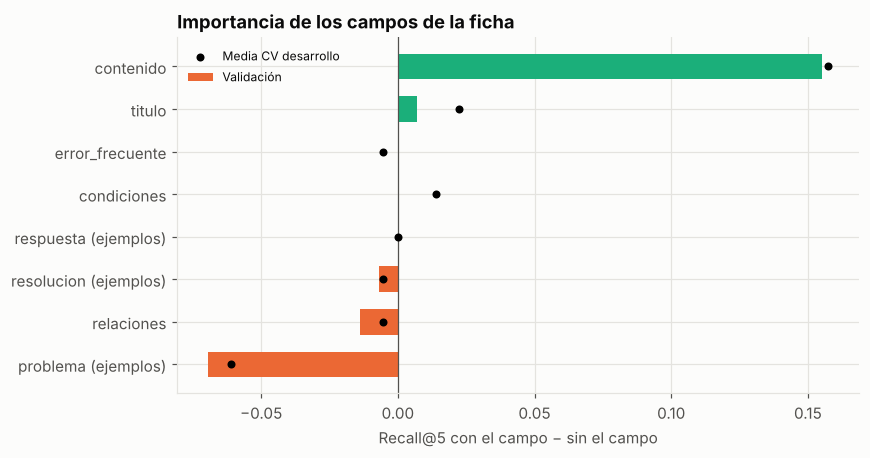

In [4]:
t = tabla_a.sort_values("importancia_val")
fig, ax = plt.subplots(figsize=(8, 4.2)); y = range(len(t))
ax.barh(y, t.importancia_val, color=[u.SERIE[2] if v > 0 else u.SERIE[1] for v in t.importancia_val], height=0.6, label="Validación")
ax.scatter(t.importancia_cv, y, color="black", s=18, zorder=3, label="Media CV desarrollo")
ax.set_yticks(list(y)); ax.set_yticklabels(t.campo); ax.axvline(0, color=u.TINTA_2, lw=0.8)
ax.set_xlabel("Recall@5 con el campo − sin el campo"); ax.set_title("Importancia de los campos de la ficha"); ax.legend(fontsize=8)
plt.show()

**Lectura.**
- **El contenido es decisivo:** sin él, el Recall@5 cae de 0,44 a 0,29 (p < 0,001). El título aporta poco. Las relaciones, las condiciones y el error frecuente casi no pesan para *buscar*, aunque sirven al LLM para *responder*.
- **El enunciado de las fichas de ejemplo resuelto estorba:** si se retira, el Recall@5 sube a 0,51 (p < 0,001). Esas fichas están escritas como problemas y ocupan lugares del top-5, pero la clave nunca las marca como esperadas. Lo comprobamos:

In [5]:
tipos = pd.Series([f.split("-")[2][0] for fs in preguntas.unidades_relevantes for f in fs]).map({"T": "teoría", "P": "procedimiento", "E": "ejemplo"})
print("Fichas esperadas en la clave, por tipo:", tipos.value_counts().to_dict())
r0 = fe.evaluar(fe.indice(iv.CFG, corpus)[0], val)
bus = fe.indice(iv.CFG, corpus)[0]
ocup = np.mean([sum(d.split("-")[2].startswith("E") for d, _ in bus.buscar(t, 5)) for t in val.enunciado])
print(f"En validación, de las 5 fichas recuperadas, en promedio {ocup:.1f} son fichas de ejemplo")

Fichas esperadas en la clave, por tipo: {'teoría': 437, 'procedimiento': 89}


En validación, de las 5 fichas recuperadas, en promedio 2.4 son fichas de ejemplo


Parte del efecto depende de esa convención de anotación. Por eso no se cambia el índice todavía: el papel de los ejemplos se evaluará como **hiperparámetro**, con CV en desarrollo, en el sprint de optimización.

## B. Variables de las preguntas: ¿qué hace fallar al buscador?

Para cada pregunta se calculan sus características, y la variable objetivo es **Fallo@5**: ninguna ficha correcta entre las 5.

La variable «solapamiento con la ficha correcta» (proporción de raíces de la pregunta que aparecen en las fichas esperadas) usa la clave. Es de **diagnóstico**: explica el fallo, pero no está disponible cuando el chatbot está en uso.

In [6]:
bus = fe.indice(iv.CFG, corpus)[0]
Xd = iv.caracteristicas(dev, corpus, fe.evaluar(bus, dev))
Xd.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
practica,0.75,0.43,0.0,1.0
nivel,0.93,0.79,0.0,2.0
material_generado,0.23,0.42,0.0,1.0
palabras_enunciado,33.21,17.30,4.0,94.0
cantidad_de_numeros,2.54,2.02,0.0,16.0
fichas_esperadas,1.44,0.52,1.0,3.0
cobertura_parcial,0.03,0.18,0.0,1.0
parecida_a_ejemplo_del_corpus,0.05,0.22,0.0,1.0
solapamiento_con_ficha_correcta,0.51,0.25,0.1,1.0
subtema_MRU,0.20,0.40,0.0,1.0


**Modelos:** regresión logística estandarizada y bosque aleatorio.
- **Entrenamiento:** solo con desarrollo.
- **Validación:** CV agrupada por familia (AUC).
- **Importancia:** por permutación sobre el holdout de validación (200 repeticiones). Mide cuánto cae el AUC si se desordena esa variable.

In [7]:
coefs, perm, auc, nb_ = iv.parte_b(corpus, dev, val)
print(json.dumps(auc, indent=1)); print(nb_)
coefs

{
 "regresion_logistica": {
  "auc_cv_desarrollo": 0.837,
  "auc_cv_de": 0.085,
  "auc_validacion": 0.866
 },
 "bosque_aleatorio": {
  "auc_cv_desarrollo": 0.844,
  "auc_cv_de": 0.061,
  "auc_validacion": 0.839
 }
}
{'n_desarrollo': 180, 'n_validacion': 72, 'fallo_desarrollo': 0.483, 'fallo_validacion': 0.486}


,variable,coeficiente_estandarizado,odds_ratio_por_1_de
8,solapamiento_con_ficha_correcta,-2.084,0.12
3,palabras_enunciado,-0.508,0.60
9,subtema_MRU,-0.323,0.72
1,nivel,-0.186,0.83
5,fichas_esperadas,-0.114,0.89
13,subtema_MCU,-0.042,0.96
10,subtema_MRUV,-0.039,0.96
11,subtema_MVCL,0.132,1.14
7,parecida_a_ejemplo_del_corpus,0.152,1.16
0,practica,0.159,1.17


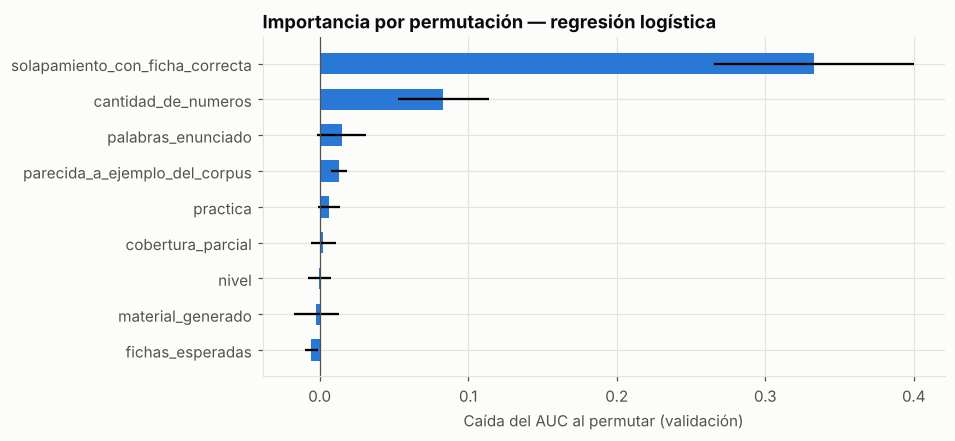

,variable,valor,tasa_fallo@5,n
0,practica,0,0.143,63
1,practica,1,0.598,189
2,subtema,MCU,0.333,51
3,subtema,MPCL,0.490,51
4,subtema,MRU,0.400,50
5,subtema,MRUV,0.640,50
6,subtema,MVCL,0.560,50
7,material_generado,0,0.596,193
8,material_generado,1,0.119,59
9,cobertura_parcial,0,0.467,242


In [8]:
p = perm[(perm.modelo == "regresion_logistica") & ~perm.variable.str.startswith("subtema_")].sort_values("importancia_auc")
fig, ax = plt.subplots(figsize=(8, 4)); y = range(len(p))
ax.barh(y, p.importancia_auc, xerr=p.de, color=u.SERIE[0], height=0.6)
ax.set_yticks(list(y)); ax.set_yticklabels(p.variable); ax.axvline(0, color=u.TINTA_2, lw=0.8)
ax.set_xlabel("Caída del AUC al permutar (validación)"); ax.set_title("Importancia por permutación — regresión logística")
plt.show()
pd.read_csv(iv.R / "tasa_fallo_por_grupo.csv")

**Lectura.**
- **El solapamiento de vocabulario con la ficha correcta es, con mucha diferencia, la variable más importante:**
  - odds ratio de 0,12 por desviación estándar;
  - tasa de fallo del 82 % en el tercil bajo frente al 12 % en el alto.
- **Los enunciados con muchos números** fallan más (odds ratio 2,8).
- Una vez controladas esas dos variables, el subtema, el nivel y ser de práctica pesan poco.

**El buscador falla cuando la pregunta no usa las palabras de la ficha.** Es el límite natural de BM25.

## Conclusiones

| Hallazgo | Acción |
|---|---|
| El contenido es lo que permite encontrar una ficha | Corpus v6: escribir el contenido también con el vocabulario de los problemas |
| El fallo se explica por la falta de palabras compartidas | Probar búsqueda semántica (embeddings) |
| Los enunciados de los ejemplos ocupan el top-5 | Evaluar el papel de los ejemplos como hiperparámetro (CV en desarrollo) |
| Muchos números → más fallo | Explorar normalizar números y unidades |